# Traveler Insights

**Curso:** Procesamiento de Lenguaje Natural · Unidad 5 — Clasificación y evaluación  
**Institución:** Universidad Tecnológica de Bolívar  
**Referencia:** Jurafsky, D. & Martin, J. H. (2025). *Speech and Language Processing* (3.ª ed.), Cap. 8 — RNNs and LSTMs  
**Datos:** competencia Kaggle *Traveler Insights UPTC 2026* (`data/traveler_insights/train.csv` y `test.csv`)  
**Compatibilidad:** Python 3.10–3.13 · PyTorch ≥ 2.0 · CPU o GPU

## Contexto y Propósito

Este notebook clasifica reseñas de lugares turísticos del departamento de Sucre (Tripadvisor y Foursquare) en tres clases de la competencia Kaggle *Traveler Insights UPTC 2026* usando **redes neuronales recurrentes**: RNN simple, LSTM, BiLSTM y LSTM con atención, con *embeddings* word2vec entrenados en el corpus y una línea base TF-IDF. Antes de modelar, **audita la etiqueta** y descubre que `Sentimiento` no describe el comentario sino la calificación promedio del lugar con escalas mezcladas; por eso valida agrupando por lugar, compara con referencias que no leen el texto y usa técnicas de interpretabilidad para detectar atajos.

**Objetivo:** aprender cómo funcionan las RNN y LSTM aplicadas a texto y, al mismo tiempo, cómo evaluar un modelo con honestidad cuando la etiqueta tiene fugas: separar lo que el modelo aprende del lenguaje de lo que aprende de la plataforma o del lugar.

## Ejemplos de Aplicación en el Mundo Real

Cada caso muestra, paso a paso, cómo se aplica la técnica de este notebook a un problema real.

### Energía e industria — Bitácoras de mantenimiento

- **Problema:** una planta quiere anticipar fallas de equipos a partir de las anotaciones de los operadores.
- **Entrada:** secuencia de anotaciones de texto por equipo.
- **Cómo se aplica RNN / LSTM:**
  1. Las anotaciones se convierten en secuencias de *embeddings* word2vec entrenados en las propias bitácoras.
  2. Una LSTM recorre la secuencia y su memoria conserva señales tempranas (`vibración`, `ruido`) hasta el final.
  3. La validación cruzada se agrupa por equipo, como aquí por lugar, para no evaluar con equipos vistos en entrenamiento.
- **Salida:** probabilidad de falla próxima por equipo.
- **Decisión:** programar mantenimiento preventivo en los equipos de mayor riesgo.

### Finanzas y servicio al cliente — Transcripciones de llamadas

- **Problema:** detectar clientes que terminan la llamada insatisfechos.
- **Entrada:** transcripción completa de la llamada.
- **Cómo se aplica RNN / LSTM:**
  1. La transcripción se trata como una secuencia larga de tokens.
  2. Una BiLSTM con atención lee en ambos sentidos y la atención señala los tramos decisivos (`ya llamé tres veces`).
  3. Antes de entrenar se audita que la etiqueta describa la llamada y no otra cosa, como hace este notebook con `Sentimiento`.
- **Salida:** riesgo de insatisfacción y frases con mayor atención.
- **Decisión:** llamada de seguimiento a los clientes de mayor riesgo.

## Requisitos Previos

**Instalación** (una sola vez, desde la terminal; en Jupyter o Colab antepón `!`):

```bash
pip install numpy pandas matplotlib scikit-learn torch gensim captum lime
```

**Librerías que se importan:**

| Librería | Para qué se usa |
|---------|-----------------|
| `html, re, time, collections, pathlib` | Utilidades de la biblioteca estándar |
| `numpy, pandas, matplotlib` | Cálculo, tablas y gráficas |
| `torch, torch.nn` | Redes recurrentes (RNN, LSTM), entrenamiento y empaquetado de secuencias |
| `gensim.models.Word2Vec` | *Embeddings* entrenados en el corpus |
| `sklearn` | TF-IDF, regresión logística, `StratifiedGroupKFold`, métricas |
| `captum.attr.LayerIntegratedGradients` | Atribuciones por token (*Integrated Gradients*) |
| `lime.lime_text.LimeTextExplainer` | Explicaciones locales con LIME |
| `IPython.display` | Resaltado de palabras en HTML |

**Datos:** `data/traveler_insights/train.csv` y `test.csv` (descargados de la competencia de Kaggle).

## Marco metodológico: CRISP-ML(Q)

Este notebook sigue **CRISP-ML(Q)** (*Cross-Industry Standard Process for the development of Machine Learning applications with Quality assurance*; Studer et al., 2021). El proceso tiene seis fases, y en cada una se identifican los riesgos de calidad y cómo se mitigan. Las fases aparecen marcadas con 🔷 a lo largo del notebook.

| Fase CRISP-ML(Q) | Dónde se aborda en este notebook | Aseguramiento de calidad |
|------------------|----------------------------------|--------------------------|
| 1. Entendimiento del negocio y de los datos | Secciones 2–3: datos y **auditoría de la etiqueta** (regla sobre la calificación del lugar, escalas mezcladas, atajos) | Referencias “tramposas” (solo sitio, solo lugar, solo longitud) para saber qué se puede lograr sin leer el sentimiento |
| 2. Ingeniería de datos | Secciones 4 y 6: tokenización, vocabulario, secuencias y word2vec | Vocabulario, word2vec y TF-IDF se ajustan dentro de cada partición |
| 3. Ingeniería del modelo | Secciones 5 y 7: teoría, experimento de gradiente y cuatro redes recurrentes | Sesgo de olvido = 1, recorte de gradiente y pesos por clase |
| 4. Aseguramiento de calidad del modelo | Secciones 8–11: CV agrupada por lugar, prueba única (lugares vistos / nuevos), errores e interpretabilidad | Se comparan los modelos contra la referencia “solo sitio” y se buscan atajos |
| 5. Despliegue | Al final (fuera de alcance) | — |
| 6. Monitoreo y mantenimiento | Al final (fuera de alcance) | — |

Conclusión principal: con esta etiqueta, los modelos miden sobre todo la capacidad de reconocer **plataforma y lugar**. Antes de desplegar algo así hay que volver a la fase 1 y reetiquetar por comentario.

## Estándares de referencia

Prácticas de este notebook alineadas con estándares de IEEE SA, ISO/IEC y la Open Source Initiative (OSI). Se citan como guía de buenas prácticas, no como certificación de cumplimiento.

| Estándar | Cómo se aplica aquí |
|----------|---------------------|
| **ISO/IEC 23894:2023** — Guía para la gestión de riesgos de IA | La sección 3 es una evaluación de riesgos de los datos: encuentra que la etiqueta es una regla sobre la calificación del lugar y mide las fugas con referencias simples. |
| **IEEE 7003-2024** — Consideraciones sobre sesgo algorítmico | Escalas /5 y /10 con los mismos umbrales producen un **sesgo sistemático por plataforma**; se documenta y se cuantifica. |
| **IEEE 2894-2024** — Guía de marco arquitectónico para IA explicable (XAI) | Coeficientes, atención, *Integrated Gradients* (con control de completitud) y LIME se comparan para explicar las predicciones y encontrar atajos. |
| **IEEE 7001-2021** — Transparencia de sistemas autónomos | Las limitaciones (etiqueta, tamaño, lugares compartidos entre train y test) se declaran junto a los resultados. |
| **IEEE 7000-2021** — Proceso modelo para abordar consideraciones éticas durante el diseño de sistemas | Las decisiones de diseño (validar por lugar, no usar la etiqueta como “sentimiento”) se justifican por su efecto sobre quienes usarían el sistema. |
| **OSI · Open Source AI Definition 1.0 (2024)** — Qué hace que un sistema de IA sea de código abierto: libertades de usar, estudiar, modificar y compartir, con acceso a código, parámetros e información de los datos | Código y librerías abiertas; los datos provienen de una competencia de Kaggle con sus propias reglas de uso. |

## Objetivos de aprendizaje

Al finalizar este notebook podrás:

1. **Auditar un conjunto de datos** antes de modelar: descubrir cómo se construyó la etiqueta y detectar fugas de información
2. Explicar cómo una **RNN** procesa una secuencia y por qué sufre el **desvanecimiento del gradiente**
3. Explicar las **compuertas de una LSTM** y el papel de su inicialización
4. Entrenar **embeddings word2vec** sobre el corpus y usarlos para inicializar una red recurrente
5. Comparar **RNN simple, LSTM, BiLSTM y LSTM con atención** contra una línea base **TF-IDF + regresión logística**, con **validación cruzada agrupada por lugar**
6. Evaluar el mejor modelo **una sola vez** en el conjunto de prueba, separando lugares vistos y no vistos
7. Interpretar las predicciones con coeficientes, atención, *Integrated Gradients* y LIME, y usarlas para **detectar atajos**

## Estructura

| Sección | Contenido |
|---------|-----------|
| 1 | Configuración del entorno |
| 2 | Datos: reseñas de lugares turísticos de Sucre (Colombia) |
| 3 | **Auditoría de la etiqueta: ¿qué mide realmente `Sentimiento`?** |
| 4 | Preprocesamiento: tokenización, vocabulario y secuencias |
| 5 | **Teoría:** RNN, desvanecimiento del gradiente, LSTM, BiLSTM y atención |
| 6 | Embeddings word2vec entrenados en el corpus |
| 7 | Modelos y función de entrenamiento |
| 8 | **Validación cruzada estratificada y agrupada por lugar (5 folds)** |
| 9 | Modelo final y evaluación en prueba |
| 10 | Análisis de errores |
| 11 | **Interpretabilidad** |
| 12 | Resumen y limitaciones |

## Protocolo experimental

```
train.csv (818 reseñas, 73 lugares) ──► Validación cruzada 5-fold estratificada y AGRUPADA por lugar
                                         en cada fold, solo con los datos de entrenamiento del fold:
                                           · vocabulario y word2vec
                                           · TF-IDF + regresión logística (línea base)
                                           · RNN, LSTM, BiLSTM, LSTM + atención
                                      ──► se elige el mejor modelo por F1 macro medio
                                      ──► modelo final: reentrenado con todo train.csv

test.csv  (351 reseñas, 57 lugares) ──► evaluación única, separando lugares vistos / no vistos en train
```

- **Agrupada por lugar** (`StratifiedGroupKFold`): todas las reseñas de un mismo lugar quedan en el mismo fold. Así la validación mide si el modelo funciona con **lugares que no ha visto**. Si las reseñas de un lugar estuvieran repartidas entre entrenamiento y validación, el modelo podría acertar solo por reconocer el lugar (sección 3).
- El **vocabulario, word2vec y TF-IDF se ajustan dentro de cada fold**, solo con los textos de entrenamiento.
- Cada red se entrena un **número fijo de épocas**, como en `bert_classifier.ipynb`, para no elegir checkpoints con el mismo fold que se reporta.
- `test.csv` trae etiquetas. Lo usamos **una sola vez**, al final.


---

## 1. Configuración del entorno

Instala las dependencias una vez desde la terminal (en Colab, con `!` delante):

```bash
pip install torch gensim captum lime scikit-learn matplotlib
```


In [13]:
import html
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from captum.attr import LayerIntegratedGradients
from gensim.models import Word2Vec
from IPython.display import HTML, display
from lime.lime_text import LimeTextExplainer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

pd.set_option('display.max_colwidth', 120)
print(f'torch: {torch.__version__}')

torch: 2.14.0+cpu


### 1.1 Configuración del experimento

`MODO_RAPIDO` se activa si no hay GPU y reduce las épocas y el costo de la interpretabilidad.

| Parámetro | Normal | `MODO_RAPIDO` | Significado |
|-----------|--------|---------------|-------------|
| `MAX_TOKENS` | 128 | 128 | Tokens por reseña que ve la red (ver sección 4) |
| `EPOCAS` | 20 | 12 | Pasadas por los datos de entrenamiento |
| `EMB_DIM` | 100 | 100 | Dimensión de los vectores word2vec |
| `HIDDEN` | 128 | 64 | Tamaño del estado oculto de la red recurrente |
| `PASOS_IG` / `MUESTRAS_LIME` | 100 / 1000 | 50 / 300 | Costo de la interpretabilidad |


In [14]:
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODO_RAPIDO = DISPOSITIVO.type == 'cpu'      # cámbialo manualmente si lo necesitas

SEMILLA = 42
N_FOLDS = 5
MAX_TOKENS = 128
EPOCAS = 12 if MODO_RAPIDO else 20
EMB_DIM = 100
HIDDEN = 64 if MODO_RAPIDO else 128
BATCH = 32
LR = 1e-3
DROPOUT = 0.3
CLIP = 1.0                    # recorte de gradiente: indispensable en redes recurrentes
MIN_FREQ = 2                  # una palabra entra al vocabulario si aparece ≥ 2 veces
PASOS_IG = 50 if MODO_RAPIDO else 100
MUESTRAS_LIME = 300 if MODO_RAPIDO else 1000

DIR_DATA = Path.cwd() / 'data' / 'traveler_insights'


def fijar_semilla(semilla=SEMILLA):
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)


fijar_semilla()
print(f'Dispositivo: {DISPOSITIVO} · MODO_RAPIDO: {MODO_RAPIDO}')
print(f'Directorio de datos: {DIR_DATA} · ¿existe?: {DIR_DATA.exists()}')

Dispositivo: cpu · MODO_RAPIDO: True
Directorio de datos: C:\Users\epuerta\OneDrive - Universidad Tecnológica de Bolívar\Apps\courseNLP\examples\data\traveler_insights · ¿existe?: True


> 🔷 **CRISP-ML(Q) · Fase 1 — Entendimiento del negocio y de los datos.** Datos de la competencia y auditoría de la etiqueta.

---

## 2. Datos: Traveler Insights

Reseñas de lugares turísticos del departamento de Sucre (Coveñas, San Onofre, Sincelejo, Tolú…) recolectadas de **Tripadvisor** y **Foursquare**.

| Columna | Contenido |
|---------|-----------|
| `Comentario` | Texto de la reseña: **la entrada de nuestros modelos** |
| `Sentimiento` | Etiqueta: `negativo`, `neutral`, `positivo` |
| `Sitio` | Plataforma de origen: Tripadvisor o Foursquare |
| `Nombre del lugar`, `Municipio` | Lugar reseñado |
| `Valoración`, `Valoración_num`, `Valoraciones` | Calificación del lugar y número de calificaciones |
| `Fecha`, `Votos a favor`, `Votos en contra`, `Precio` | Otros metadatos |


In [15]:
train = pd.read_csv(DIR_DATA / 'train.csv')
test = pd.read_csv(DIR_DATA / 'test.csv')
for df in (train, test):
    df['Municipio'] = df['Municipio'].str.strip()
    df['Comentario'] = df['Comentario'].fillna('').astype(str)

CLASES = ['negativo', 'neutral', 'positivo']
CLASE2ID = {c: i for i, c in enumerate(CLASES)}
ID2CLASE = dict(enumerate(CLASES))
NUM_CLASES = len(CLASES)
train['label'] = train['Sentimiento'].map(CLASE2ID)
test['label'] = test['Sentimiento'].map(CLASE2ID)

print(f'train: {train.shape} · test: {test.shape}')
print(f'Lugares distintos · train: {train["Nombre del lugar"].nunique()} · test: {test["Nombre del lugar"].nunique()}')
print(f'Comentarios repetidos dentro de train: {train["Comentario"].duplicated().sum()} · '
      f'comentarios de test que también están en train: {test["Comentario"].isin(train["Comentario"]).sum()}')

pd.DataFrame({
    'train (n)': train['Sentimiento'].value_counts().reindex(CLASES),
    'train (%)': (train['Sentimiento'].value_counts(normalize=True).reindex(CLASES) * 100).round(1),
    'test (n)': test['Sentimiento'].value_counts().reindex(CLASES),
    'test (%)': (test['Sentimiento'].value_counts(normalize=True).reindex(CLASES) * 100).round(1),
})

train: (818, 16) · test: (351, 16)
Lugares distintos · train: 73 · test: 57
Comentarios repetidos dentro de train: 9 · comentarios de test que también están en train: 3


,train (n),train (%),test (n),test (%)
Sentimiento,,,,
negativo,22,2.7,10,2.8
neutral,639,78.1,274,78.1
positivo,157,19.2,67,19.1


> **Interpretación de la salida:**
>
> - **Desbalance extremo:** ~78 % neutral, ~19 % positivo y menos del 3 % negativo (22 reseñas en train y 10 en test). Un modelo que siempre dijera “neutral” tendría ~78 % de *accuracy* y un F1 macro de ~0.29. Por eso usamos **F1 macro** y **pesos de clase**.
> - Hay algunos comentarios repetidos dentro de train y unos pocos que aparecen en train y en test. Son pocos, pero conviene saberlo.


In [16]:
pd.concat([g.sample(2, random_state=SEMILLA) for _, g in train.groupby('Sentimiento')])[
    ['Sentimiento', 'Sitio', 'Nombre del lugar', 'Valoración', 'Comentario']]

,Sentimiento,Sitio,Nombre del lugar,Valoración,Comentario
35,negativo,Tripadvisor,Plaza de Majagual,3.5/5,"Plaza Majagual No es lugar seguro para visitar ni limpio no le hacen aseo a diario, hay días que se ve limpia y días..."
572,negativo,Tripadvisor,Ecoparque Laderas de Villeros Coveñas,3.5/5,"Coveñas me pareció un lugar tranquilo, mar limpio, con playas similares a Bocagrande, pero en mejor estado. No dudar..."
107,neutral,Tripadvisor,Salto del Sereno,4.5/5,"Esta fue una experiencia muy linda, sobre todo por ser un lugar de Colombia aún inexplorado por muchos y no sale nad..."
436,neutral,Tripadvisor,Isla Múcura,4.5/5,INCREÍBLE Esta isla no tiene comparación si quieres tener una muy buena y relajantes vacaciones. Sin duda lo recomie...
640,positivo,Foursquare,Parrilla Bar,7.6/10,Espectacular elsolomilloa lasfinas hierbas.
246,positivo,Foursquare,Rincón del Mar,8.9/10,Bucear desde lacabañade Juan. Ir a Titipan a pasar la tarde y tomar uncóctel


> **Antes de seguir, lee los ejemplos:** ¿la etiqueta coincide con lo que expresa el comentario? Si una reseña muy elogiosa aparece como `neutral`, o una queja como `positivo`, algo en la construcción de la etiqueta merece revisión. La siguiente sección lo investiga.


---

## 3. Auditoría de la etiqueta: ¿qué mide realmente `Sentimiento`?

Antes de entrenar cualquier modelo hay que entender **de dónde sale la etiqueta**. Si depende de algo distinto al texto, el modelo puede obtener métricas altas sin aprender lo que creemos.

### 3.1 ¿La etiqueta es una regla sobre `Valoración_num`?


In [17]:
todo = pd.concat([train.assign(conjunto='train'), test.assign(conjunto='test')], ignore_index=True)

regla = pd.cut(todo['Valoración_num'], bins=[-np.inf, 4, 7, np.inf], right=False, labels=CLASES).astype(str)
print(f'Reseñas cuya etiqueta coincide con la regla  <4 → negativo · [4, 7) → neutral · ≥7 → positivo: '
      f'{(regla == todo["Sentimiento"]).mean():.1%}\n')

print(todo.groupby('Sentimiento')['Valoración_num'].agg(['min', 'max', 'count']).reindex(CLASES).to_string())

Reseñas cuya etiqueta coincide con la regla  <4 → negativo · [4, 7) → neutral · ≥7 → positivo: 100.0%

             min  max  count
Sentimiento                 
negativo     3.5  3.5     32
neutral      4.0  6.9    913
positivo     7.0  8.9    224


> **Interpretación de la salida:** si la coincidencia es del 100 %, la etiqueta **no fue anotada leyendo el comentario**: se obtiene con umbrales sobre `Valoración_num`. Los rangos de cada clase no se solapan.


### 3.2 ¿`Valoración_num` describe la reseña o el lugar?


In [18]:
por_lugar = todo.groupby('Nombre del lugar').agg(
    resenas=('Comentario', 'size'),
    valoraciones_distintas=('Valoración_num', 'nunique'),
    etiquetas_distintas=('Sentimiento', 'nunique'),
)
print(f'Lugares: {len(por_lugar)} · con una sola Valoración_num para todas sus reseñas: '
      f'{(por_lugar["valoraciones_distintas"] == 1).sum()}')
print(f'Lugares cuyas reseñas tienen todas la misma etiqueta: {(por_lugar["etiquetas_distintas"] == 1).sum()}\n')

todo[todo['Nombre del lugar'] == todo['Nombre del lugar'].value_counts().index[0]][
    ['Nombre del lugar', 'Valoración', 'Valoraciones', 'Sentimiento', 'Comentario']].head(4)

Lugares: 80 · con una sola Valoración_num para todas sus reseñas: 78
Lugares cuyas reseñas tienen todas la misma etiqueta: 78



,Nombre del lugar,Valoración,Valoraciones,Sentimiento,Comentario
0,Isla Múcura,4.5/5,281,neutral,"La isla es muy hermosa y tiene unas aguas muy azuladas; pero mi consejo es que se cuiden de las personas, pues la ma..."
3,Isla Múcura,4.5/5,281,neutral,es un paraíso de playa Para llegar a la isla llegamos a Tolu nos hospedamos en un excelente hotel llamado hotel Cari...
5,Isla Múcura,4.5/5,281,neutral,"Un lugar paradisiaco!!!! Si pensás que haz visto todo y conoces los mejores lugares, si no haz ido a esta isla te va..."
10,Isla Múcura,4.5/5,281,neutral,"Un lujo Después de la isla San Andrés lo mejor de Colombia, tranquilidad garantizada y seguridad, no se usan llaves ..."


> **Interpretación de la salida:**
>
> - `Valoración` (“4.5/5”) y `Valoraciones` (“281”) se repiten **en todas las reseñas de un mismo lugar**: son el **promedio del lugar** en la plataforma, no la calificación que dio el autor del comentario.
> - Por tanto, **todas las reseñas de un lugar llevan la misma etiqueta**, sin importar lo que digan. Una reseña negativa sobre un lugar con 4.5/5 queda como `neutral`.


### 3.3 Escalas mezcladas: Tripadvisor (/5) y Foursquare (/10)


In [19]:
todo['escala'] = '/' + todo['Valoración'].str.split('/').str[1]
print(pd.crosstab(todo['Sitio'], todo['escala']).to_string(), '\n')
pd.crosstab(todo['Sitio'], todo['Sentimiento']).reindex(columns=CLASES)

escala       /10   /5
Sitio                
Foursquare   289    0
Tripadvisor    0  880 



Sentimiento,negativo,neutral,positivo
Sitio,,,
Foursquare,0,65,224
Tripadvisor,32,848,0


> **Interpretación de la salida:**
>
> - Tripadvisor califica **sobre 5** y Foursquare **sobre 10**, pero se les aplicaron **los mismos umbrales** (4 y 7).
> - Consecuencia: en Tripadvisor ninguna reseña puede ser `positivo` (el máximo es 5.0/5, que cae en `neutral`), y en Foursquare ninguna es `negativo`.
> - Así, **la plataforma determina en gran parte la clase**: `positivo` ⇒ Foursquare, `negativo` ⇒ Tripadvisor. Un 5.0/5 de Tripadvisor (excelente) termina como `neutral`, mientras que un 7.2/10 de Foursquare termina como `positivo`.


In [20]:
print('¿De qué lugares vienen las reseñas negativas?')
todo[todo['Sentimiento'] == 'negativo'].groupby(['Nombre del lugar', 'Sitio', 'Valoración']).size().to_frame('reseñas')

¿De qué lugares vienen las reseñas negativas?


,,,reseñas
Nombre del lugar,Sitio,Valoración,
Ecoparque Laderas de Villeros Coveñas,Tripadvisor,3.5/5,4
Plaza de Majagual,Tripadvisor,3.5/5,28


> **Interpretación de la salida:** todos los negativos vienen de **muy pocos lugares** de Tripadvisor con calificación baja. Para el modelo, “negativo” significa en la práctica “reseña de ese lugar en Tripadvisor”. Con validación agrupada, en varios folds **no habrá ningún negativo** en validación, y en otros el entrenamiento tendrá apenas unos cuantos.


### 3.4 ¿Se puede predecir la etiqueta sin leer el sentimiento?

Probamos tres “modelos tramposos” en el conjunto de prueba, todos entrenados con `train.csv`:

1. **Solo el sitio:** predice la etiqueta más frecuente de cada plataforma en train (Tripadvisor → la suya, Foursquare → la suya).
2. **Solo el lugar:** predice la etiqueta más frecuente del lugar en train. Si el lugar no aparece en train, predice la clase mayoritaria.
3. **Solo la longitud:** regresión logística sobre el número de palabras del comentario.
4. **Detectar la plataforma desde el texto:** TF-IDF + regresión logística para predecir `Sitio` a partir del `Comentario`. Si funciona bien, el texto “delata” la plataforma, y con ella buena parte de la etiqueta.


In [21]:
def f1m(y_real, y_pred):
    return f1_score(y_real, y_pred, average='macro', zero_division=0)


def regla_sitio(df_entrenamiento, df_a_predecir):
    # Etiqueta más frecuente de cada plataforma en el entrenamiento.
    moda = df_entrenamiento.groupby('Sitio')['label'].agg(lambda s: s.mode()[0])
    return df_a_predecir['Sitio'].map(moda).fillna(df_entrenamiento['label'].mode()[0]).astype(int).to_numpy()


def n_palabras(df):
    return np.log1p(df['Comentario'].apply(lambda t: len(re.findall(r'\w+', t)))).to_frame()


# 1) Solo el sitio
pred_sitio = regla_sitio(train, test)

# 2) Solo el lugar
mayoritaria = train['label'].mode()[0]
etiqueta_lugar = train.groupby('Nombre del lugar')['label'].agg(lambda s: s.mode()[0])
lugar_visto = test['Nombre del lugar'].isin(etiqueta_lugar.index)
pred_lugar = test['Nombre del lugar'].map(etiqueta_lugar).fillna(mayoritaria).astype(int)

# 3) Solo la longitud
pred_longitud = LogisticRegression().fit(n_palabras(train), train['label']).predict(n_palabras(test))

# 4) Plataforma desde el texto
tfidf_sitio = TfidfVectorizer(sublinear_tf=True, min_df=2)
lr_sitio = LogisticRegression(max_iter=2000, class_weight='balanced').fit(
    tfidf_sitio.fit_transform(train['Comentario']), train['Sitio'])
pred_plataforma = lr_sitio.predict(tfidf_sitio.transform(test['Comentario']))

print(f'Reseñas de test cuyo lugar aparece en train: {lugar_visto.mean():.1%}\n')
pd.DataFrame({
    'F1 macro (Sentimiento)': [f1m(test['label'], pred_sitio), f1m(test['label'], pred_lugar),
                               f1m(test['label'][lugar_visto], pred_lugar[lugar_visto]),
                               f1m(test['label'], pred_longitud)],
    'accuracy (Sentimiento)': [accuracy_score(test['label'], pred_sitio), accuracy_score(test['label'], pred_lugar),
                               accuracy_score(test['label'][lugar_visto], pred_lugar[lugar_visto]),
                               accuracy_score(test['label'], pred_longitud)],
}, index=['1) solo Sitio', '2) solo lugar (todo test)', '2) solo lugar (lugares vistos)', '3) solo longitud']).round(3)

Reseñas de test cuyo lugar aparece en train: 97.7%



,F1 macro (Sentimiento),accuracy (Sentimiento)
1) solo Sitio,0.597,0.906
2) solo lugar (todo test),0.914,0.972
2) solo lugar (lugares vistos),0.927,0.983
3) solo longitud,0.542,0.866


In [22]:
print(f'4) Predecir la plataforma desde el texto · accuracy: {accuracy_score(test["Sitio"], pred_plataforma):.3f} · '
      f'F1 macro: {f1_score(test["Sitio"], pred_plataforma, average="macro"):.3f}')

4) Predecir la plataforma desde el texto · accuracy: 0.940 · F1 macro: 0.919


> **Cómo interpretar la salida:**
>
> - **Solo el sitio** (Foursquare → `positivo`, Tripadvisor → `neutral`) alcanza una *accuracy* alta sin leer una palabra: confirma que la plataforma decide casi toda la clase. Su F1 macro es la **referencia mínima** para cualquier modelo de texto.
> - **Solo el lugar** logra un F1 macro de ~0.91 y una *accuracy* de ~0.97, porque la etiqueta es constante por lugar y **casi el 98 % de las reseñas de test son de lugares que ya están en train**. Una partición aleatoria (no agrupada) daría métricas **infladas** por memorización de lugares.
> - **Solo la longitud:** los “tips” de Foursquare son muy cortos (mediana ~7 palabras) y las reseñas de Tripadvisor largas (~35). La longitud sola ya separa buena parte de `positivo` y `neutral`.
> - **Plataforma desde el texto:** con una *accuracy* ~0.94, el texto revela casi siempre de qué plataforma viene: por la longitud, el estilo y artefactos de extracción. En Foursquare hay palabras pegadas como *lahamburguesa* o *elpatacón*. Así el modelo de “sentimiento” obtiene una pista fuerte sin leer el sentimiento.


### 3.5 Conclusión de la auditoría y decisiones

| Hallazgo | Consecuencia | Qué hacemos |
|----------|--------------|-------------|
| La etiqueta es una regla sobre la calificación **promedio del lugar** | No es sentimiento del comentario: es “¿qué tan bien calificado está el lugar en su plataforma?” | Mantenemos la etiqueta de la competencia, pero **interpretamos los resultados con esa definición** |
| Escalas /5 y /10 con los mismos umbrales | La plataforma determina gran parte de la clase | Comparamos los modelos con la referencia “solo Sitio” |
| Todas las reseñas de un lugar comparten etiqueta | Una partición aleatoria permite memorizar lugares | **Validación cruzada agrupada por lugar** |
| Test comparte la mayoría de lugares con train | La prueba final también puede inflarse | Reportamos test separado en **lugares vistos / no vistos** |
| Negativos de muy pocos lugares | La clase `negativo` es casi imposible de aprender de forma general | Lo veremos en las métricas por clase |

> 💡 **Lección:** antes de comparar arquitecturas hay que preguntar **qué mide la etiqueta**. Ningún modelo, por sofisticado que sea, aprende sentimiento si la etiqueta no lo contiene.


> 🔷 **CRISP-ML(Q) · Fase 2 — Ingeniería de datos.** Tokenización, vocabulario, secuencias (y word2vec en la sección 6).

---

## 4. Preprocesamiento: de texto a secuencias de índices

1. **Tokenizar:** minúsculas y palabras (se conservan tildes y ñ).
2. **Vocabulario:** palabras con frecuencia ≥ `MIN_FREQ` en el **entrenamiento del fold**. Índices reservados: `0 = <pad>` (relleno) y `1 = <unk>` (desconocida).
3. **Codificar y truncar** a `MAX_TOKENS`.
4. **Rellenar por lote** y empaquetar con `pack_padded_sequence`, para que la red **no procese el relleno**.


In [23]:
PAD, UNK = '<pad>', '<unk>'


def tokenizar(texto):
    return re.findall(r'\w+', texto.lower())


class Vocabulario:
    def __init__(self, documentos, min_freq=MIN_FREQ):
        conteo = Counter(t for doc in documentos for t in doc)
        self.itos = [PAD, UNK] + sorted(t for t, c in conteo.items() if c >= min_freq)
        self.stoi = {t: i for i, t in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def codificar(self, tokens, max_len=MAX_TOKENS):
        return [self.stoi.get(t, 1) for t in tokens[:max_len]] or [1]


train['tokens'] = train['Comentario'].apply(tokenizar)
test['tokens'] = test['Comentario'].apply(tokenizar)
longitudes = train['tokens'].str.len()

print(longitudes.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_string())
print(f'\nReseñas que superan MAX_TOKENS={MAX_TOKENS}: {(longitudes > MAX_TOKENS).mean():.1%}')
print('\nTokens por clase (mediana):', train.assign(n=longitudes).groupby('Sentimiento')['n'].median().to_dict())
print('Tokens por sitio (mediana):', train.assign(n=longitudes).groupby('Sitio')['n'].median().to_dict())

vocab_demo = Vocabulario(train['tokens'])
print(f'\nVocabulario (todo train, solo como demostración): {len(vocab_demo)} tokens')
print(f'Ejemplo: {train.loc[0, "tokens"][:8]} → {vocab_demo.codificar(train.loc[0, "tokens"])[:8]}')

count    818.0
mean      41.0
std       45.7
min        1.0
50%       28.0
90%       83.3
95%      121.0
99%      228.7
max      542.0

Reseñas que superan MAX_TOKENS=128: 4.8%

Tokens por clase (mediana): {'negativo': 25.5, 'neutral': 34.0, 'positivo': 7.0}
Tokens por sitio (mediana): {'Foursquare': 7.0, 'Tripadvisor': 35.0}

Vocabulario (todo train, solo como demostración): 2124 tokens
Ejemplo: ['la', 'isla', 'es', 'muy', 'hermosa', 'y', 'tiene', 'unas'] → [1095, 1070, 753, 1275, 960, 2103, 1918, 2006]


> **Interpretación de la salida:**
>
> - Las reseñas son cortas (mediana de ~28 palabras). Con `MAX_TOKENS = 128` se trunca un porcentaje pequeño.
> - Compara la longitud por clase y por sitio. Si una plataforma escribe reseñas sistemáticamente más largas, la **longitud** es otra pista para identificarla, y por tanto para adivinar la clase.


In [24]:
def crear_lote(ejemplos):
    secuencias, etiquetas = zip(*ejemplos)
    longitudes = torch.tensor([len(s) for s in secuencias])
    ids = torch.zeros(len(secuencias), longitudes.max(), dtype=torch.long)
    for i, s in enumerate(secuencias):
        ids[i, :len(s)] = torch.tensor(s)
    return ids, longitudes, torch.tensor(etiquetas)


def crear_loader(secuencias, etiquetas, barajar):
    return torch.utils.data.DataLoader(
        list(zip(secuencias, etiquetas)), batch_size=BATCH, shuffle=barajar, collate_fn=crear_lote,
        generator=torch.Generator().manual_seed(SEMILLA),
    )


ids, lon, y_lote = next(iter(crear_loader([vocab_demo.codificar(t) for t in train['tokens'][:4]],
                                          train['label'][:4].tolist(), barajar=False)))
print(f'ids: {tuple(ids.shape)} · longitudes: {lon.tolist()} · etiquetas: {y_lote.tolist()}')

ids: (4, 128) · longitudes: [29, 6, 33, 128] · etiquetas: [1, 2, 1, 1]


> **Interpretación de la salida:** el lote tiene forma `(4, L)`, con `L` igual a la reseña más larga **de ese lote**. Las longitudes reales le indican a `pack_padded_sequence` dónde termina cada secuencia, para que el último estado oculto corresponda al último token real y no al relleno.


> 🔷 **CRISP-ML(Q) · Fase 3 — Ingeniería del modelo.** Teoría de RNN y LSTM, *embeddings*, arquitecturas y entrenamiento.

---

## 5. Teoría: de la RNN a la LSTM

### 5.1 RNN simple (Elman)

Una RNN lee la secuencia token a token y mantiene un **estado oculto** $h_t$ que resume lo leído:

$$h_t = \tanh\left(W_{hh}\, h_{t-1} + W_{xh}\, x_t + b\right)$$

Para clasificar usamos el último estado: $\hat{y} = \text{softmax}(W_o\, h_T)$. Los mismos pesos se aplican en **todos** los pasos.

### 5.2 Desvanecimiento del gradiente

El gradiente respecto a un token lejano atraviesa todos los pasos intermedios:

$$\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \text{diag}\big(1 - h_k^2\big)\, W_{hh}$$

Es un producto de $T - t$ matrices. Si sus normas son menores que 1, el producto **decae exponencialmente**: los primeros tokens casi no influyen en el aprendizaje.

### 5.3 LSTM (Hochreiter & Schmidhuber, 1997)

La LSTM añade una **celda de memoria** $c_t$ controlada por tres compuertas con valores entre 0 y 1:

| Compuerta | Ecuación | Función |
|-----------|----------|---------|
| Olvido | $f_t = \sigma(W_f [h_{t-1}, x_t] + b_f)$ | Qué parte de la memoria anterior conservar |
| Entrada | $i_t = \sigma(W_i [h_{t-1}, x_t] + b_i)$ | Cuánto de la información nueva escribir |
| Candidato | $\tilde{c}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$ | Información nueva propuesta |
| Salida | $o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$ | Qué parte de la memoria exponer |

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \qquad h_t = o_t \odot \tanh(c_t)$$

La clave es la suma en $c_t$: si $f_t \approx 1$, el gradiente fluye por la celda **casi sin atenuarse** ($\partial c_t / \partial c_{t-1} = f_t$).

### 5.4 BiLSTM

Dos LSTM leen la secuencia en sentidos opuestos, y la representación concatena ambos estados finales: $h = [\overrightarrow{h}_T ; \overleftarrow{h}_1]$.

### 5.5 LSTM con atención

En lugar de usar solo $h_T$, la atención calcula un **promedio ponderado de todos los estados**:

$$e_t = v^\top \tanh(W_a h_t) \qquad \alpha_t = \frac{\exp(e_t)}{\sum_{k} \exp(e_k)} \qquad z = \sum_t \alpha_t\, h_t$$

Los pesos $\alpha_t$ indican qué posiciones usa el modelo para decidir. Los inspeccionaremos en la sección 11, con las mismas precauciones de `bert_classifier.ipynb`: la atención no es una explicación causal.


### 5.6 Experimento: ¿cuánto gradiente llega a los primeros tokens?

Pasamos una secuencia aleatoria de 100 pasos por redes **sin entrenar** y medimos $\|\partial h_T / \partial x_t\|$ en cada posición $t$, es decir, cuánto puede influir el token $t$ en el estado final.

1. **RNN simple**
2. **LSTM con la inicialización por defecto** de PyTorch: la compuerta de olvido empieza en $f_t \approx \sigma(0) = 0.5$
3. **LSTM con sesgo de olvido = 1** ($f_t \approx 0.73$), práctica recomendada por Jozefowicz et al. (2015) y que usamos en nuestros modelos


RNN simple                         · t=0: 0.0e+00 · t=50: 3.7e-19 · t=99: 4.0e-01
LSTM (inicialización por defecto)  · t=0: 0.0e+00 · t=50: 1.6e-12 · t=99: 2.0e-01
LSTM (sesgo de olvido = 1)         · t=0: 1.3e-11 · t=50: 8.4e-07 · t=99: 1.9e-01


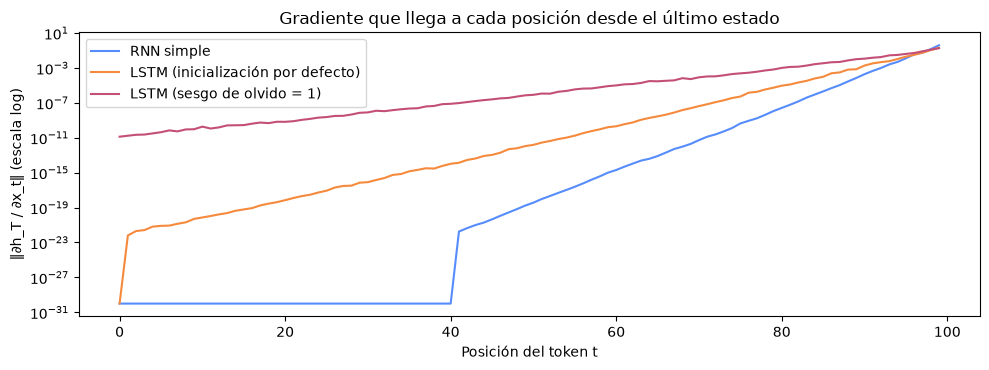

In [25]:
def sesgo_olvido_uno(lstm):
    # PyTorch ordena las compuertas como [entrada, olvido, candidato, salida] dentro de cada sesgo.
    with torch.no_grad():
        for nombre, param in lstm.named_parameters():
            if 'bias' in nombre:
                h = param.shape[0] // 4
                param[h:2 * h] = 0.5          # sesgo_ih + sesgo_hh = 1
    return lstm


fijar_semilla()
T, D, H = 100, EMB_DIM, HIDDEN
x = torch.randn(1, T, D, requires_grad=True)
redes = [
    ('RNN simple', nn.RNN(D, H, batch_first=True)),
    ('LSTM (inicialización por defecto)', nn.LSTM(D, H, batch_first=True)),
    ('LSTM (sesgo de olvido = 1)', sesgo_olvido_uno(nn.LSTM(D, H, batch_first=True))),
]

fig, ax = plt.subplots(figsize=(10, 3.8))
for nombre, red in redes:
    x.grad = None
    salida, _ = red(x)
    salida[0, -1].norm().backward()
    normas = x.grad[0].norm(dim=1).numpy()
    ax.semilogy(range(T), np.maximum(normas, 1e-30), label=nombre)
    print(f'{nombre:34s} · t=0: {normas[0]:.1e} · t={T // 2}: {normas[T // 2]:.1e} · t={T - 1}: {normas[-1]:.1e}')

ax.set_xlabel('Posición del token t')
ax.set_ylabel('‖∂h_T / ∂x_t‖ (escala log)')
ax.set_title('Gradiente que llega a cada posición desde el último estado')
ax.legend()
plt.tight_layout()
plt.show()

> **Cómo interpretar la salida:**
>
> - El eje vertical es **logarítmico**: cada división es un factor de 10. Los valores 0 en precisión de máquina se dibujan en $10^{-30}$.
> - En la **RNN simple**, la curva cae en picada al alejarse del final: los primeros tokens prácticamente no reciben gradiente.
> - La **LSTM con inicialización por defecto** decae más despacio, pero **también se desvanece**: con $f_t \approx 0.5$ la celda pierde la mitad de su contenido en cada paso.
> - Con **sesgo de olvido = 1** el gradiente decae mucho más despacio: a mitad de la secuencia es varios órdenes de magnitud mayor. La arquitectura LSTM **permite** recordar a largo plazo, y una buena inicialización la pone en condiciones de hacerlo desde el principio.
> - Con reseñas de ~30 tokens el problema es menos grave que en textos largos, pero la diferencia entre la RNN y la LSTM sigue presente.


---

## 6. Embeddings word2vec entrenados en el corpus

word2vec (Mikolov et al., 2013; Jurafsky & Martin, §6.8) aprende un vector denso por palabra prediciendo su contexto. Usamos **skip-gram** (`sg=1`), que funciona mejor que CBOW con corpus pequeños.

- **Oraciones de entrenamiento:** cada reseña es una oración.
- **Solo textos de entrenamiento:** en la validación cruzada, word2vec se reentrena en cada fold.
- La matriz de *embeddings* de la red se **inicializa** con estos vectores y se sigue ajustando. Las palabras sin vector se inicializan al azar.


In [27]:
def entrenar_word2vec(documentos):
    return Word2Vec([d for d in documentos if d], vector_size=EMB_DIM, window=5, min_count=MIN_FREQ, sg=1,
                    epochs=20, workers=1, seed=SEMILLA)


def matriz_embeddings(vocab, w2v):
    rng = np.random.default_rng(SEMILLA)
    matriz = rng.normal(0, 0.1, size=(len(vocab), EMB_DIM)).astype(np.float32)
    matriz[0] = 0.0
    cubiertas = 0
    for i, palabra in enumerate(vocab.itos):
        if palabra in w2v.wv:
            matriz[i] = w2v.wv[palabra]
            cubiertas += 1
    return torch.tensor(matriz), cubiertas / len(vocab)


inicio = time.time()
w2v_demo = entrenar_word2vec(train['tokens'])
_, cobertura = matriz_embeddings(vocab_demo, w2v_demo)
print(f'word2vec: {len(w2v_demo.wv)} palabras · {time.time() - inicio:.1f} s · cobertura del vocabulario: {cobertura:.1%}')

consultas = ['playa', 'excelente', 'malo', 'sucio', 'comida', 'servicio', 'caro', 'hermosa']
pd.DataFrame([
    {'palabra': p, 'vecinos más cercanos (coseno)':
        ', '.join(f'{v} ({s:.2f})' for v, s in w2v_demo.wv.most_similar(p, topn=6)) if p in w2v_demo.wv
        else '— no está en el vocabulario —'}
    for p in consultas
]).set_index('palabra')

word2vec: 2122 palabras · 2.5 s · cobertura del vocabulario: 99.9%


,vecinos más cercanos (coseno)
palabra,
playa,"vista (0.81), pública (0.81), piscina (0.80), transparente (0.79), desconectarse (0.79), oleaje (0.79)"
excelente,"manuel (0.83), capacitado (0.82), brinda (0.81), cordial (0.80), relación (0.79), brindan (0.79)"
malo,"caro (0.92), caliente (0.92), balsillas (0.92), cuidan (0.90), apto (0.90), precioso (0.90)"
sucio,"pintoresco (0.98), húmedo (0.97), devolverte (0.97), ceja (0.97), directo (0.97), leche (0.97)"
comida,"deliciosa (0.79), rica (0.79), típica (0.78), habitaciones (0.76), ofrecen (0.74), caribeña (0.73)"
servicio,"cordial (0.80), relación (0.78), brinda (0.77), guía (0.77), atención (0.77), rápido (0.76)"
caro,"complementa (0.96), balsillas (0.95), apto (0.95), deportes (0.95), obligado (0.94), espectáculo (0.94)"
hermosa,"pequeña (0.84), iglesia (0.84), mas (0.83), aún (0.82), preciosa (0.80), limpia (0.79)"


> **Cómo interpretar la salida:**
>
> - El corpus tiene solo unas decenas de miles de palabras, muy poco para word2vec (que suele entrenarse con millones). Los vecinos serán **ruidosos**: palabras que aparecen en las mismas reseñas o lugares, no necesariamente sinónimos.
> - Por ejemplo, *playa* aparecerá cerca de nombres de lugares costeros. Eso refleja co-ocurrencia temática, no semántica general.
> - Con un corpus así de pequeño, un word2vec preentrenado en español (como SBWC) daría mejores vectores. Aquí lo entrenamos en el corpus para mostrar el proceso completo.


---

## 7. Modelos y función de entrenamiento

### 7.1 Arquitectura común

```
ids ─► Embedding (word2vec) ─► Dropout ─► RNN / LSTM / BiLSTM ─► representación ─► Dropout ─► Lineal ─► 3 logits
                                                  └─ (LSTM+atención: promedio ponderado de todos los estados)
```

| `tipo` | Capa recurrente | Representación | Parámetros recurrentes |
|--------|-----------------|----------------|------------------------|
| `rnn` | `nn.RNN` (tanh) | $h_T$ | $(D + H) \cdot H$ |
| `lstm` | `nn.LSTM` | $h_T$ | $4 \cdot (D + H) \cdot H$ |
| `bilstm` | `nn.LSTM(bidirectional=True)` | $[\overrightarrow{h}_T ; \overleftarrow{h}_1]$ | el doble que `lstm` |
| `lstm_att` | `nn.LSTM` | $\sum_t \alpha_t h_t$ | `lstm` + atención |


In [28]:
class ClasificadorRecurrente(nn.Module):
    def __init__(self, tipo, embeddings, num_clases=NUM_CLASES, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.tipo = tipo
        self.embedding = nn.Embedding.from_pretrained(embeddings, freeze=False, padding_idx=0)
        dim = embeddings.shape[1]
        bidireccional = tipo == 'bilstm'
        if tipo == 'rnn':
            self.rnn = nn.RNN(dim, hidden, batch_first=True, nonlinearity='tanh')
        else:
            self.rnn = sesgo_olvido_uno(nn.LSTM(dim, hidden, batch_first=True, bidirectional=bidireccional))
        salida = hidden * (2 if bidireccional else 1)
        if tipo == 'lstm_att':
            self.att_W = nn.Linear(hidden, hidden)
            self.att_v = nn.Linear(hidden, 1, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.clasificador = nn.Linear(salida, num_clases)
        self.pesos_atencion = None

    def forward(self, ids, longitudes):
        x = self.dropout(self.embedding(ids))
        empaquetado = pack_padded_sequence(x, longitudes.cpu(), batch_first=True, enforce_sorted=False)
        salidas, estado = self.rnn(empaquetado)
        h_n = estado[0] if isinstance(estado, tuple) else estado      # LSTM devuelve (h, c)

        if self.tipo == 'lstm_att':
            H_t, _ = pad_packed_sequence(salidas, batch_first=True, total_length=ids.shape[1])
            puntajes = self.att_v(torch.tanh(self.att_W(H_t))).squeeze(-1)
            mascara = torch.arange(ids.shape[1], device=ids.device)[None, :] < longitudes.to(ids.device)[:, None]
            alfa = torch.softmax(puntajes.masked_fill(~mascara, float('-inf')), dim=1)
            self.pesos_atencion = alfa.detach()
            z = (alfa.unsqueeze(-1) * H_t).sum(dim=1)
        elif self.tipo == 'bilstm':
            z = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            z = h_n[-1]
        return self.clasificador(self.dropout(z))


emb_demo, _ = matriz_embeddings(vocab_demo, w2v_demo)
for tipo in ['rnn', 'lstm', 'bilstm', 'lstm_att']:
    m = ClasificadorRecurrente(tipo, emb_demo)
    n_rec = sum(p.numel() for n, p in m.named_parameters() if not n.startswith('embedding'))
    print(f'{tipo:9s} · parámetros sin contar embeddings: {n_rec:>9,}')
print(f'embeddings: {emb_demo.numel():,} parámetros ({emb_demo.shape[0]} palabras × {EMB_DIM})')

rnn       · parámetros sin contar embeddings:    10,819
lstm      · parámetros sin contar embeddings:    42,691
bilstm    · parámetros sin contar embeddings:    85,379
lstm_att  · parámetros sin contar embeddings:    46,915
embeddings: 212,400 parámetros (2124 palabras × 100)


> **Interpretación de la salida:** la LSTM tiene ~4 veces más parámetros recurrentes que la RNN simple, y la BiLSTM el doble que la LSTM. Con solo ~650 reseñas de entrenamiento por fold, más parámetros también significa más riesgo de **sobreajuste**: memorizar reseñas en vez de generalizar.


### 7.2 Entrenamiento

| Decisión | Valor | Por qué |
|----------|-------|---------|
| Pérdida | Entropía cruzada **con pesos de clase** $w_k = N / (K \cdot N_k)$ | Con 3 % de negativos, sin pesos el modelo ignoraría esa clase |
| Optimizador | Adam, `lr=1e-3` | Estándar para redes recurrentes desde cero |
| Recorte de gradiente | norma máxima `CLIP = 1.0` | Evita la **explosión del gradiente** |
| Épocas | fijas (`EPOCAS`) | No elegimos checkpoints con el fold de validación |


In [29]:
def pesos_clase(etiquetas):
    conteo = np.bincount(etiquetas, minlength=NUM_CLASES).astype(float)
    conteo[conteo == 0] = 1.0
    return torch.tensor(len(etiquetas) / (NUM_CLASES * conteo), dtype=torch.float32)


def entrenar_red(tipo, embeddings, sec_tr, y_tr, verbose=False):
    fijar_semilla()
    modelo = ClasificadorRecurrente(tipo, embeddings).to(DISPOSITIVO)
    optim = torch.optim.Adam(modelo.parameters(), lr=LR)
    perdida_fn = nn.CrossEntropyLoss(weight=pesos_clase(np.array(y_tr)).to(DISPOSITIVO))
    loader = crear_loader(sec_tr, y_tr, barajar=True)
    historial = []
    for epoca in range(EPOCAS):
        modelo.train()
        total = 0.0
        for ids, lon, y_b in loader:
            ids, y_b = ids.to(DISPOSITIVO), y_b.to(DISPOSITIVO)
            optim.zero_grad()
            perdida = perdida_fn(modelo(ids, lon), y_b)
            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), CLIP)
            optim.step()
            total += perdida.item() * len(y_b)
        historial.append(total / len(y_tr))
        if verbose and (epoca + 1) % 4 == 0:
            print(f'  época {epoca + 1:2d}/{EPOCAS} · pérdida de entrenamiento: {historial[-1]:.4f}')
    return modelo, historial


@torch.no_grad()
def predecir_red(modelo, secuencias):
    modelo.eval()
    probs = []
    for ids, lon, _ in crear_loader(secuencias, [0] * len(secuencias), barajar=False):
        probs.append(torch.softmax(modelo(ids.to(DISPOSITIVO), lon), dim=-1).cpu().numpy())
    return np.vstack(probs)


def metricas(y_real, y_pred):
    # F1 macro sobre las clases presentes en y_real o y_pred (sklearn por defecto).
    p, r, f1, _ = precision_recall_fscore_support(y_real, y_pred, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_real, y_pred), 'f1_macro': f1, 'precision_macro': p, 'recall_macro': r}


def linea_base_tfidf():
    return TfidfVectorizer(tokenizer=tokenizar, token_pattern=None, lowercase=False, min_df=MIN_FREQ,
                           ngram_range=(1, 2), sublinear_tf=True)

> 🔷 **CRISP-ML(Q) · Fase 4 — Aseguramiento de calidad del modelo.** Validación cruzada agrupada, prueba final, errores e interpretabilidad.

---

## 8. Validación cruzada estratificada y agrupada por lugar (5 folds)

`StratifiedGroupKFold` reparte los **lugares** en 5 grupos intentando conservar la proporción de clases. En cada fold, con los datos de entrenamiento del fold:

1. se construyen el vocabulario y word2vec;
2. se entrena la línea base **TF-IDF (unigramas + bigramas) + regresión logística**;
3. se entrenan las **4 redes** con los mismos datos.

Además registramos la referencia **solo Sitio** de la sección 3.4 en cada fold.


In [30]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
y_tr_all = train['label'].to_numpy()
grupos = train['Nombre del lugar'].to_numpy()
folds = list(sgkf.split(train, y_tr_all, grupos))

resumen_folds = pd.DataFrame([
    {'fold': f, 'lugares val.': len(set(grupos[i_va])), 'reseñas val.': len(i_va),
     **{f'val {c}': int((y_tr_all[i_va] == k).sum()) for k, c in enumerate(CLASES)},
     'negativos en entrenamiento': int((y_tr_all[i_tr] == 0).sum()),
     '¿lugar compartido?': bool(set(grupos[i_tr]) & set(grupos[i_va]))}
    for f, (i_tr, i_va) in enumerate(folds, start=1)
]).set_index('fold')
resumen_folds

,lugares val.,reseñas val.,val negativo,val neutral,val positivo,negativos en entrenamiento,¿lugar compartido?
fold,,,,,,,
1,10,174,0,143,31,22,False
2,19,151,0,119,32,22,False
3,10,171,0,140,31,22,False
4,19,168,19,118,31,3,False
5,15,154,3,119,32,19,False


> **Interpretación de la salida:**
>
> - `¿lugar compartido?` debe ser `False` en todos los folds: ningún lugar aparece en entrenamiento y validación a la vez.
> - Los negativos se concentran en muy pocos folds de validación, porque vienen de muy pocos lugares. En los folds sin negativos, el F1 macro se calcula con las clases presentes. En el fold que contiene la mayoría de negativos, el modelo se entrena con **muy pocos ejemplos** de esa clase.


In [31]:
MODELOS = ['rnn', 'lstm', 'bilstm', 'lstm_att']
resultados = []
oof = {nombre: np.zeros((len(train), NUM_CLASES)) for nombre in ['solo_sitio', 'tfidf_lr'] + MODELOS}
historiales = {m: [] for m in MODELOS}

for fold, (i_tr, i_va) in enumerate(folds, start=1):
    print(f'\n===== Fold {fold}/{N_FOLDS} · entrenamiento={len(i_tr)} · validación={len(i_va)} =====')
    tr, va = train.iloc[i_tr], train.iloc[i_va]

    # Referencia: solo Sitio
    pred_s = regla_sitio(tr, va)
    oof['solo_sitio'][i_va] = np.eye(NUM_CLASES)[pred_s]
    resultados.append({'fold': fold, 'modelo': 'solo_sitio', **metricas(va['label'], pred_s), 'segundos': 0.0})

    # Línea base TF-IDF + regresión logística
    inicio = time.time()
    tfidf = linea_base_tfidf()
    X_tr, X_va = tfidf.fit_transform(tr['Comentario']), tfidf.transform(va['Comentario'])
    lr = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEMILLA).fit(X_tr, tr['label'])
    oof['tfidf_lr'][np.ix_(i_va, lr.classes_)] = lr.predict_proba(X_va)
    resultados.append({'fold': fold, 'modelo': 'tfidf_lr', **metricas(va['label'], lr.predict(X_va)),
                       'segundos': time.time() - inicio})

    # Vocabulario y word2vec solo con el entrenamiento del fold
    vocab = Vocabulario(tr['tokens'])
    emb, cobertura = matriz_embeddings(vocab, entrenar_word2vec(tr['tokens']))
    sec_tr = [vocab.codificar(t) for t in tr['tokens']]
    sec_va = [vocab.codificar(t) for t in va['tokens']]
    print(f'vocabulario: {len(vocab)} · cobertura word2vec: {cobertura:.1%} · '
          f'solo_sitio F1={resultados[-2]["f1_macro"]:.3f} · tfidf_lr F1={resultados[-1]["f1_macro"]:.3f}')

    for tipo in MODELOS:
        inicio = time.time()
        modelo, hist = entrenar_red(tipo, emb, sec_tr, tr['label'].tolist())
        probs = predecir_red(modelo, sec_va)
        oof[tipo][i_va] = probs
        historiales[tipo].append(hist)
        res = {'fold': fold, 'modelo': tipo, **metricas(va['label'], probs.argmax(1)), 'segundos': time.time() - inicio}
        resultados.append(res)
        print(f'  {tipo:9s} · F1 macro={res["f1_macro"]:.3f} · accuracy={res["accuracy"]:.3f} · {res["segundos"]:.0f} s')
        del modelo

cv = pd.DataFrame(resultados)


===== Fold 1/5 · entrenamiento=644 · validación=174 =====
vocabulario: 1839 · cobertura word2vec: 99.9% · solo_sitio F1=1.000 · tfidf_lr F1=0.819
  rnn       · F1 macro=0.589 · accuracy=0.931 · 14 s
  lstm      · F1 macro=0.909 · accuracy=0.943 · 17 s
  bilstm    · F1 macro=0.624 · accuracy=0.960 · 34 s
  lstm_att  · F1 macro=0.539 · accuracy=0.856 · 19 s

===== Fold 2/5 · entrenamiento=667 · validación=151 =====
vocabulario: 1864 · cobertura word2vec: 99.9% · solo_sitio F1=0.842 · tfidf_lr F1=0.709
  rnn       · F1 macro=0.431 · accuracy=0.636 · 10 s
  lstm      · F1 macro=0.478 · accuracy=0.775 · 29 s
  bilstm    · F1 macro=0.498 · accuracy=0.815 · 60 s
  lstm_att  · F1 macro=0.482 · accuracy=0.801 · 25 s

===== Fold 3/5 · entrenamiento=647 · validación=171 =====


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocabulario: 1696 · cobertura word2vec: 99.9% · solo_sitio F1=1.000 · tfidf_lr F1=0.875
  rnn       · F1 macro=0.634 · accuracy=0.965 · 10 s
  lstm      · F1 macro=0.659 · accuracy=0.988 · 30 s
  bilstm    · F1 macro=0.626 · accuracy=0.959 · 36 s
  lstm_att  · F1 macro=0.951 · accuracy=0.971 · 21 s

===== Fold 4/5 · entrenamiento=650 · validación=168 =====
vocabulario: 1806 · cobertura word2vec: 99.9% · solo_sitio F1=0.549 · tfidf_lr F1=0.494
  rnn       · F1 macro=0.437 · accuracy=0.655 · 9 s
  lstm      · F1 macro=0.471 · accuracy=0.708 · 18 s
  bilstm    · F1 macro=0.564 · accuracy=0.738 · 31 s
  lstm_att  · F1 macro=0.490 · accuracy=0.744 · 26 s

===== Fold 5/5 · entrenamiento=664 · validación=154 =====
vocabulario: 1796 · cobertura word2vec: 99.9% · solo_sitio F1=0.620 · tfidf_lr F1=0.550
  rnn       · F1 macro=0.526 · accuracy=0.844 · 14 s
  lstm      · F1 macro=0.500 · accuracy=0.708 · 19 s
  bilstm    · F1 macro=0.535 · accuracy=0.812 · 41 s
  lstm_att  · F1 macro=0.521 · accur

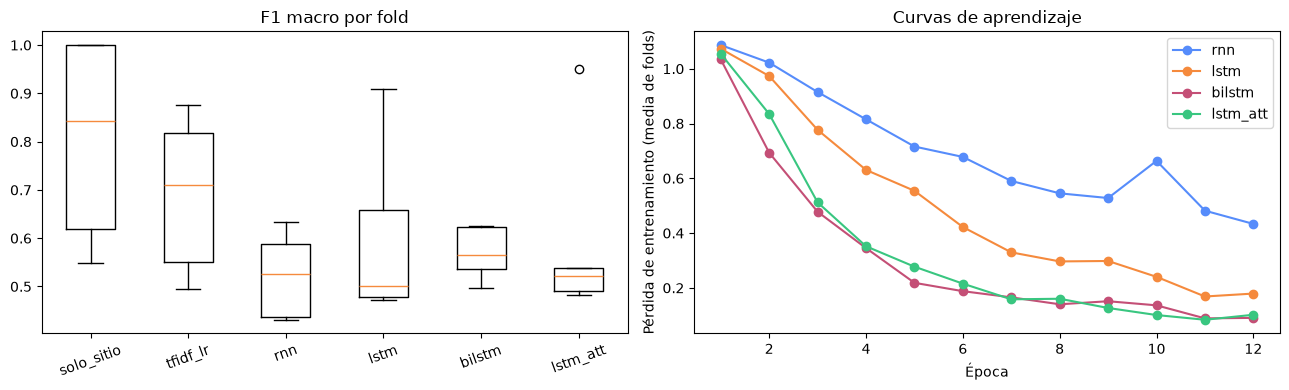

,F1 macro (media ± desv.),F1 macro out-of-fold,accuracy mean,recall_macro mean,segundos mean
modelo,,,,,
solo_sitio,0.802 ± 0.210,0.610,0.920,0.838,0.000
tfidf_lr,0.690 ± 0.165,0.529,0.851,0.689,0.172
rnn,0.524 ± 0.090,0.519,0.806,0.542,11.205
lstm,0.603 ± 0.187,0.540,0.824,0.627,22.609
bilstm,0.570 ± 0.056,0.602,0.857,0.569,40.232
lstm_att,0.597 ± 0.200,0.532,0.839,0.620,22.530


In [32]:
orden = ['solo_sitio', 'tfidf_lr'] + MODELOS
tabla_cv = cv.groupby('modelo')[['f1_macro', 'accuracy', 'recall_macro', 'segundos']].agg(['mean', 'std']).loc[orden]
tabla_cv.columns = [f'{m} {s}' for m, s in tabla_cv.columns]
tabla_cv['F1 macro (media ± desv.)'] = [f'{a:.3f} ± {b:.3f}' for a, b in zip(tabla_cv['f1_macro mean'], tabla_cv['f1_macro std'])]
tabla_cv['F1 macro out-of-fold'] = [f1m(y_tr_all, oof[m].argmax(1)) for m in orden]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
datos_box = [cv.loc[cv['modelo'] == m, 'f1_macro'] for m in orden]
ejes[0].boxplot(datos_box)
ejes[0].set_xticks(range(1, len(orden) + 1), orden)
ejes[0].set_title('F1 macro por fold')
ejes[0].tick_params(axis='x', rotation=20)
for tipo in MODELOS:
    ejes[1].plot(range(1, EPOCAS + 1), np.mean(historiales[tipo], axis=0), marker='o', label=tipo)
ejes[1].set_xlabel('Época')
ejes[1].set_ylabel('Pérdida de entrenamiento (media de folds)')
ejes[1].set_title('Curvas de aprendizaje')
ejes[1].legend()
plt.tight_layout()
plt.show()

tabla_cv[['F1 macro (media ± desv.)', 'F1 macro out-of-fold', 'accuracy mean', 'recall_macro mean', 'segundos mean']].round(3)

> **Cómo interpretar la salida** (las cifras citadas son de una ejecución en CPU con `MODO_RAPIDO`; en GPU cambian algo, pero el patrón se mantiene):
>
> - **Primero compara todo con `solo_sitio`.** En nuestra ejecución, esa referencia, que **no lee el texto**, obtuvo F1 macro ≈ 0.80, **por encima de todos los modelos de texto** (TF-IDF ≈ 0.69, LSTM ≈ 0.68, BiLSTM ≈ 0.56, RNN ≈ 0.50). Saber de qué plataforma viene la reseña predice la etiqueta mejor que leerla, lo que confirma la auditoría de la sección 3.
> - **TF-IDF vs. redes:** con ~650 reseñas cortas por fold, TF-IDF + regresión logística es tan buena o mejor que las redes, y miles de veces más rápida.
> - **RNN simple vs. LSTM:** la RNN simple queda por debajo de las variantes LSTM, en línea con la sección 5.
> - **La desviación es enorme** (± 0.25 en la LSTM): el F1 cambia mucho según el fold. El fold que concentra los negativos (19 en validación y solo 3 en entrenamiento) es el peor para todos los modelos.
> - **Curvas de aprendizaje:** si la pérdida de entrenamiento llega casi a 0, las redes **memorizan** el entrenamiento (sobreajuste).


In [33]:
mejor = tabla_cv.loc[MODELOS, 'f1_macro mean'].idxmax()
print(f'Mejor red según F1 macro medio: {mejor}\n')
for nombre in ['tfidf_lr', mejor]:
    print(f'--- {nombre} (predicciones out-of-fold de los 5 folds) ---')
    print(classification_report(y_tr_all, oof[nombre].argmax(1), labels=range(NUM_CLASES),
                                target_names=CLASES, digits=3, zero_division=0))

Mejor red según F1 macro medio: lstm

--- tfidf_lr (predicciones out-of-fold de los 5 folds) ---
              precision    recall  f1-score   support

    negativo      0.000     0.000     0.000        22
     neutral      0.890     0.926     0.908       639
    positivo      0.691     0.669     0.680       157

    accuracy                          0.852       818
   macro avg      0.527     0.532     0.529       818
weighted avg      0.828     0.852     0.840       818

--- lstm (predicciones out-of-fold de los 5 folds) ---
              precision    recall  f1-score   support

    negativo      0.000     0.000     0.000        22
     neutral      0.935     0.853     0.892       639
    positivo      0.639     0.847     0.729       157

    accuracy                          0.829       818
   macro avg      0.525     0.567     0.540       818
weighted avg      0.853     0.829     0.837       818



> **Cómo interpretar la salida:** el reporte junta las predicciones de los 5 folds.
>
> - **`negativo` tiene *recall* 0** en ambos modelos. No es un fallo de la arquitectura: los negativos son reseñas de dos lugares concretos, y con validación agrupada el modelo **nunca ha visto ese lugar** cuando lo evalúa. No hay un “sentimiento negativo” general que aprender, porque la etiqueta no lo mide.
> - **`positivo`** va mejor porque coincide con Foursquare, cuyo estilo (tips cortos) es fácil de reconocer.


---

## 9. Modelo final y evaluación en prueba

Reentrenamos con **todo `train.csv`** la mejor red y la línea base TF-IDF, y evaluamos ambas **una sola vez** en `test.csv`. Si la mejor red no es `lstm_att`, entrenamos también una `lstm_att` final solo para analizar su atención en la sección 11.

Reportamos test completo y separado en **lugares vistos en train** y **lugares nuevos**: es la forma de ver cuánto del desempeño viene de reconocer lugares.


In [34]:
vocab_final = Vocabulario(train['tokens'])
emb_final, _ = matriz_embeddings(vocab_final, entrenar_word2vec(train['tokens']))
sec_train = [vocab_final.codificar(t) for t in train['tokens']]
sec_test = [vocab_final.codificar(t) for t in test['tokens']]
y_test = test['label'].to_numpy()

modelos_finales = {}
for tipo in dict.fromkeys([mejor, 'lstm_att']):
    print(f'Entrenando {tipo} con todo train...')
    modelos_finales[tipo], _ = entrenar_red(tipo, emb_final, sec_train, train['label'].tolist(), verbose=True)
modelo_final = modelos_finales[mejor]
probs_test = predecir_red(modelo_final, sec_test)
pred_test = probs_test.argmax(1)

tfidf_final = linea_base_tfidf()
X_train = tfidf_final.fit_transform(train['Comentario'])
lr_final = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEMILLA).fit(X_train, train['label'])
pred_lr_test = lr_final.predict(tfidf_final.transform(test['Comentario']))

visto = test['Nombre del lugar'].isin(set(train['Nombre del lugar'])).to_numpy()
filas = {}
for nombre, pred in [('solo_sitio', pred_sitio), ('tfidf_lr', pred_lr_test), (mejor, pred_test)]:
    filas[nombre] = {
        'CV F1 macro (media)': tabla_cv.loc[nombre, 'f1_macro mean'],
        'test F1 macro': f1m(y_test, pred),
        'test accuracy': accuracy_score(y_test, pred),
        f'F1 lugares vistos (n={visto.sum()})': f1m(y_test[visto], pred[visto]),
        f'F1 lugares nuevos (n={(~visto).sum()})': f1m(y_test[~visto], pred[~visto]),
    }
pd.DataFrame(filas).T.round(3)

Entrenando lstm con todo train...
  época  4/12 · pérdida de entrenamiento: 0.6989
  época  8/12 · pérdida de entrenamiento: 0.5114
  época 12/12 · pérdida de entrenamiento: 0.3273
Entrenando lstm_att con todo train...
  época  4/12 · pérdida de entrenamiento: 0.5663
  época  8/12 · pérdida de entrenamiento: 0.2418
  época 12/12 · pérdida de entrenamiento: 0.1209


,CV F1 macro (media),test F1 macro,test accuracy,F1 lugares vistos (n=343),F1 lugares nuevos (n=8)
solo_sitio,0.802,0.597,0.906,0.597,0.873
tfidf_lr,0.690,0.770,0.886,0.771,0.750
lstm,0.603,0.636,0.892,0.637,0.733


> **Cómo interpretar la salida** (cifras de nuestra ejecución en CPU):
>
> - **TF-IDF sube de ≈ 0.69 en CV a ≈ 0.77 en test.** No es que generalice mejor: el 98 % de test son **lugares vistos**. Entre ellos está Plaza de Majagual, de donde salen casi todos los negativos, y TF-IDF aprendió su vocabulario (sección 11.1). En test sí acierta algunos negativos; en CV, con el lugar oculto, no acertaba ninguno.
> - **La LSTM (≈ 0.57) queda por debajo de `solo_sitio` (≈ 0.60) en test.** La red más compleja no supera a una regla que solo mira la plataforma.
> - **Lugares nuevos:** solo hay 8 reseñas de lugares no vistos, demasiado pocas para concluir algo. Es otra consecuencia del diseño del conjunto: el test casi no mide generalización a lugares nuevos.
> - **Conclusión del experimento:** con esta etiqueta, el desempeño mide sobre todo la capacidad de reconocer **plataforma y lugar**, no sentimiento.


---

## 10. Análisis de errores


              precision    recall  f1-score   support

    negativo      1.000     0.100     0.182        10
     neutral      0.937     0.927     0.932       274
    positivo      0.734     0.866     0.795        67

    accuracy                          0.892       351
   macro avg      0.890     0.631     0.636       351
weighted avg      0.900     0.892     0.884       351



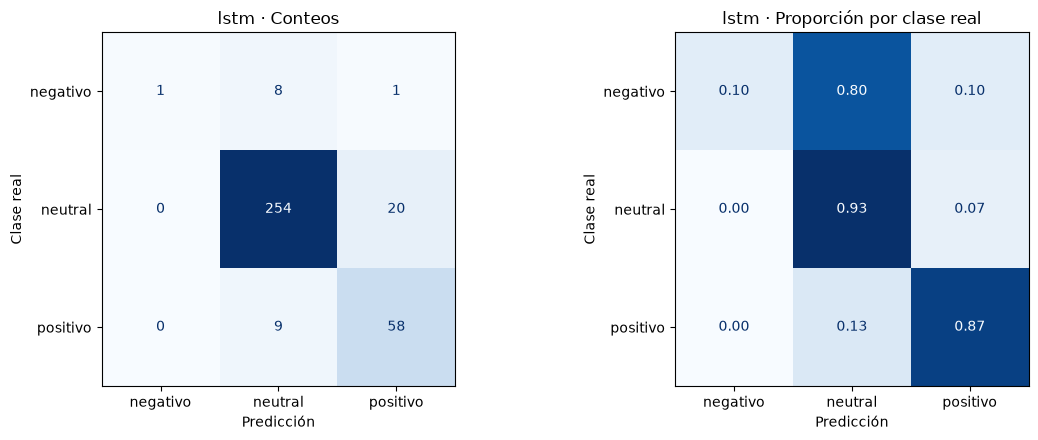

Errores por sitio:
col_0        acierto  error
Sitio                      
Foursquare     0.722  0.278
Tripadvisor    0.950  0.050


In [35]:
print(classification_report(y_test, pred_test, labels=range(NUM_CLASES), target_names=CLASES, digits=3, zero_division=0))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, normalizar, titulo in [(ejes[0], None, 'Conteos'), (ejes[1], 'true', 'Proporción por clase real')]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred_test, labels=range(NUM_CLASES), display_labels=CLASES, normalize=normalizar,
        values_format='d' if normalizar is None else '.2f', cmap='Blues', ax=eje, colorbar=False,
    )
    eje.set_title(f'{mejor} · {titulo}')
    eje.set_xlabel('Predicción')
    eje.set_ylabel('Clase real')
plt.tight_layout()
plt.show()

print('Errores por sitio:')
print(pd.crosstab(test['Sitio'], pred_test != y_test, normalize='index').rename(columns={False: 'acierto', True: 'error'}).round(3).to_string())

In [36]:
errores = test.assign(prediccion=[ID2CLASE[i] for i in pred_test], confianza=probs_test.max(1), lugar_visto=visto)
errores = errores[errores['Sentimiento'] != errores['prediccion']]
print(f'Errores: {len(errores)} de {len(test)}')
errores.sort_values('confianza', ascending=False)[
    ['Comentario', 'Sitio', 'Nombre del lugar', 'Valoración', 'Sentimiento', 'prediccion', 'confianza', 'lugar_visto']].head(10)

Errores: 38 de 351


,Comentario,Sitio,Nombre del lugar,Valoración,Sentimiento,prediccion,confianza,lugar_visto
111,Mejor atención que en Bogota. Recomendación: Chiken and Bacon Ranch Melt con Pan Caliente. De postre Galletas con Ch...,Foursquare,Subway,6.7/10,neutral,positivo,0.987522,True
222,"Recomiendo pizza lomo Stroganoff, pepperoni especial y liles especial",Foursquare,Lile's Pizza,6.7/10,neutral,positivo,0.978061,True
34,Si vienes a Corozal esta visita no puede faltar....recomendados todos!!,Foursquare,Pitufilandia,6.8/10,neutral,positivo,0.973414,True
265,"Paraíso terrenal, a solo 10- 20 minutos del municipio de San Onofre- Sucre.",Foursquare,Rincón del Mar,8.9/10,positivo,neutral,0.972582,True
161,"Según la época del año se dice que se encuentran allí diferentes eventos, cuando la visitamos en enero había grupos ...",Tripadvisor,Plaza de Majagual,3.5/5,negativo,neutral,0.972332,True
169,Hola Juan P. Estoy en interesado en viajar a Balsillas y alquilar algo. Tienes informacion de algun hotel o cabaña p...,Foursquare,Balsillas,7.3/10,positivo,neutral,0.971447,True
42,Los precios y el tamaño de las pizzas son muy buenas. Se demoran en limpiar las mesas.,Foursquare,Celupizza,7.3/10,positivo,neutral,0.967004,True
163,"Visité las playas de Coveñas en enero de 2016. Estuve en el hotel Puntepiedra y nadé en el mar del Golfo de Coveñas,...",Tripadvisor,Ecoparque Laderas de Villeros Coveñas,3.5/5,negativo,neutral,0.966597,True
346,"Una plaza muy típica de ciudades intermedias colombianas, vale la pena visitarla en las tardes de fin de semana para...",Tripadvisor,Plaza de Majagual,3.5/5,negativo,neutral,0.965909,True
316,Hermosos atardeceres. Rico alquilar una carpa y estar todo el día. Puedes almorzar bien ahí mismo y terminar la tard...,Foursquare,Playas de Coveñas,8.8/10,positivo,neutral,0.965616,True


> **Cómo interpretar la salida:**
>
> - **Matriz de confusión:** revisa si los errores siguen la frontera de las plataformas (confundir `positivo` con `neutral` suele ser confundir Foursquare con Tripadvisor).
> - **Errores con alta confianza:** lee los comentarios. Varios de estos “errores” pueden ser **aciertos razonables** respecto al texto: un comentario elogioso de Tripadvisor que el modelo marca `positivo`, mientras la etiqueta dice `neutral` porque así lo dicta la regla de la sección 3. Es la diferencia entre lo que la etiqueta mide y lo que esperaríamos de “sentimiento”.


---

## 11. Interpretabilidad

Usamos cuatro técnicas para responder: **¿en qué se apoya el modelo?** Buscamos explícitamente **atajos**: nombres de lugares, palabras típicas de una plataforma o rasgos de estilo.

| Técnica | Qué mide | Alcance |
|---------|----------|---------|
| **Coeficientes TF-IDF + LR** | Peso lineal de cada palabra o bigrama para cada clase | Global |
| **Atención** (`lstm_att`) | En qué posiciones se apoya la representación final | Local y agregada |
| ***Integrated Gradients*** | Contribución de cada token a la probabilidad de la clase predicha | Local y agregada |
| **LIME** | Cuánto cambia la predicción al borrar cada palabra | Local y agregada |


In [37]:
MIN_DOCS = 3     # una palabra entra a los rankings agregados si aparece en ≥ 3 reseñas analizadas
N_INTERP = 60 if MODO_RAPIDO else len(test)
idx_interp = np.random.default_rng(SEMILLA).choice(len(test), size=min(N_INTERP, len(test)), replace=False)


def agregar(contribuciones, k=10, min_docs=MIN_DOCS):
    # contribuciones: lista de (clase_predicha, {palabra: valor}) → top-k palabras por clase predicha.
    filas = {}
    for clase in range(NUM_CLASES):
        suma, docs = Counter(), Counter()
        for c, d in contribuciones:
            if c == clase:
                for p, v in d.items():
                    suma[p] += v
                    docs[p] += 1
        validas = {p: suma[p] / docs[p] for p in suma if docs[p] >= min_docs}
        top = sorted(validas, key=validas.get, reverse=True)[:k]
        filas[ID2CLASE[clase]] = ', '.join(top) if top else '— sin suficientes reseñas —'
    return pd.Series(filas)


def resaltar(palabras, valores, titulo=''):
    escala = np.abs(valores).max() or 1.0
    spans = []
    for p, v in zip(palabras, valores):
        a = min(abs(v) / escala, 1.0) * 0.85
        color = f'rgba(46,160,67,{a:.2f})' if v >= 0 else f'rgba(214,39,40,{a:.2f})'
        spans.append(f'<span title="{v:+.3f}" style="background:{color};padding:2px 4px;margin:1px;'
                     f'border-radius:3px;color:inherit">{html.escape(p)}</span>')
    return f'<div style="margin:6px 0 14px 0;line-height:2"><b>{html.escape(titulo)}</b><br>{" ".join(spans)}</div>'


# Ejemplos individuales: un acierto seguro por clase predicha y el error más seguro
ejemplos = []
for k in range(NUM_CLASES):
    cand = np.where((pred_test == k) & (y_test == k))[0]
    if len(cand):
        ejemplos.append(int(cand[probs_test[cand, k].argmax()]))
if len(errores):
    ejemplos.append(int(errores['confianza'].idxmax()))
print(f'Reseñas para rankings agregados: {len(idx_interp)} · ejemplos individuales: {ejemplos}')

Reseñas para rankings agregados: 60 · ejemplos individuales: [26, 11, 43, 111]


### 11.1 Coeficientes de la línea base TF-IDF + regresión logística

La regresión logística multiclase aprende un vector de pesos por clase. Las palabras y bigramas con mayor coeficiente son los que más empujan hacia esa clase. Es una interpretación **global** y exacta para ese modelo lineal.


In [38]:
vocab_tfidf = tfidf_final.get_feature_names_out()
top_coef = {ID2CLASE[c]: ', '.join(vocab_tfidf[np.argsort(lr_final.coef_[j])[::-1][:12]])
            for j, c in enumerate(lr_final.classes_)}
pd.Series(top_coef, name='TF-IDF + LR (coeficientes)').to_frame()

,TF-IDF + LR (coeficientes)
negativo,"plaza, eventos, amigos, fiestas, esa plaza, conversar, esa, juegos, culturales, nada, iluminación, lugar"
neutral,"experiencia, del, las, buceo, isla, que, una, playa, muy, son, mar, la"
positivo,"sincelejo, delicioso, excelente, comida, mejor, carne, deliciosos, recomiendo, playaslimpias, lanegrita, punto, sincé"


> **Cómo interpretar la salida:** pregúntate para cada palabra si expresa **sentimiento**, si es el **nombre o tema de un lugar** o si es un **rasgo de la plataforma**.
>
> - **`negativo`:** *plaza, eventos, fiestas, esa plaza, juegos, culturales, iluminación…* No son palabras negativas: describen **Plaza de Majagual** y sus fiestas de enero. El modelo aprendió “negativo = hablar de esa plaza”.
> - **`neutral`:** *experiencia, buceo, isla, playa, mar…* Son los temas de los lugares de Tripadvisor con buena calificación (Isla Múcura, centros de buceo).
> - **`positivo`:** aquí sí hay palabras de sentimiento (*delicioso, excelente, recomiendo*), pero porque abundan en los tips de comida de Foursquare. También hay nombres de lugares (*sincelejo, sincé*) y **palabras pegadas** por un error de extracción típico de Foursquare (*playaslimpias, lanegrita*), una huella de la plataforma.


### 11.2 Atención de `lstm_att`

Multiplicamos los pesos $\alpha_t$ por la longitud de la reseña, para que un valor > 1 signifique “más atención que el promedio”, y promediamos por aparición de cada palabra y por clase predicha.


In [39]:
modelo_att = modelos_finales['lstm_att'].eval()


@torch.no_grad()
def atencion(i):
    ids = torch.tensor([sec_test[i]], device=DISPOSITIVO)
    lon = torch.tensor([len(sec_test[i])])
    clase = int(modelo_att(ids, lon).argmax())
    alfa = modelo_att.pesos_atencion[0, :len(sec_test[i])].cpu().numpy() * len(sec_test[i])
    return clase, alfa


contrib_att = []
for i in idx_interp:
    clase, alfa = atencion(i)
    suma, veces = Counter(), Counter()
    for tok, a in zip(test.loc[i, 'tokens'][:MAX_TOKENS], alfa):
        suma[tok] += a
        veces[tok] += 1
    contrib_att.append((clase, {p: suma[p] / veces[p] for p in suma}))
top_att = agregar(contrib_att).rename('Atención (lstm_att)')

for i in ejemplos:
    clase, alfa = atencion(i)
    display(HTML(resaltar(test.loc[i, 'tokens'][:MAX_TOKENS], alfa - 1,
                          f'[{i}] lstm_att predice {ID2CLASE[clase]} · real: {test.loc[i, "Sentimiento"]} · {test.loc[i, "Sitio"]}')))
top_att.to_frame()

,Atención (lstm_att)
negativo,— sin suficientes reseñas —
neutral,"pena, aves, san, más, viaje, guía, mejores, vivir, amables, buceo"
positivo,"atención, de, la"


> **Cómo interpretar la salida:** en los ejemplos, verde = más atención que el promedio y rojo = menos. Recuerda que la atención indica **dónde mira** el modelo, no **por qué decide**. Contrástala con IG y LIME.


### 11.3 *Integrated Gradients* sobre la mejor red

La atribución de cada token se integra a lo largo del camino entre una **línea base** y la reseña real, sobre la capa de *embeddings*.

**Un problema propio de las redes recurrentes:** al recorrer ese camino, una LSTM entrenada puede cambiar de decisión **de golpe**, en un tramo diminuto. La integral numérica no capta ese salto y la **completitud** falla: la suma de las atribuciones queda lejos de $F(x) - F(x')$. Por eso:

1. probamos dos líneas base, todo `<pad>` (vectores cero) y todo `<unk>`, y elegimos la de menor error;
2. medimos el **error relativo** $|\text{suma} - \Delta F| / |\Delta F|$ y descartamos de los rankings las reseñas con error > `MAX_ERROR_IG`.

En GPU desactivamos cuDNN durante el cálculo, porque su *backward* de RNN solo funciona en modo entrenamiento.


In [40]:
MAX_ERROR_IG = 0.10
modelo_final.eval()
lig = LayerIntegratedGradients(lambda ids, lon, clase: torch.softmax(modelo_final(ids, lon), -1)[:, clase],
                               modelo_final.embedding)


def ig_resena(secuencia):
    ids = torch.tensor([secuencia], device=DISPOSITIVO)
    lon = torch.tensor([len(secuencia)])
    with torch.no_grad():
        prob = torch.softmax(modelo_final(ids, lon), -1)[0]
    clase = int(prob.argmax())
    mejor_res = None
    for nombre_base, indice in [('<pad>', 0), ('<unk>', 1)]:
        base = torch.full_like(ids, indice)
        with torch.no_grad():
            delta_F = float(prob[clase] - torch.softmax(modelo_final(base, lon), -1)[0, clase])
        with torch.backends.cudnn.flags(enabled=False):
            attr = lig.attribute(ids, baselines=base, additional_forward_args=(lon, clase),
                                 n_steps=PASOS_IG, internal_batch_size=PASOS_IG)
        puntajes = attr.sum(-1)[0].detach().cpu().numpy()
        error = abs(puntajes.sum() - delta_F) / max(abs(delta_F), 1e-6)
        if mejor_res is None or error < mejor_res[3]:
            mejor_res = (clase, puntajes, nombre_base, error)
    return mejor_res


contrib_ig, registro_ig = [], []
for i in idx_interp:
    clase, puntajes, base, error = ig_resena(sec_test[i])
    registro_ig.append({'base': base, 'error': error, 'aceptada': error <= MAX_ERROR_IG})
    if error <= MAX_ERROR_IG:
        suma = Counter()
        for tok, v in zip(test.loc[i, 'tokens'][:MAX_TOKENS], puntajes):
            suma[tok] += v
        contrib_ig.append((clase, dict(suma)))
registro_ig = pd.DataFrame(registro_ig)
print(f'Reseñas con atribución fiable (error ≤ {MAX_ERROR_IG:.0%}): {registro_ig["aceptada"].sum()} de {len(registro_ig)} · '
      f'error relativo mediano: {registro_ig["error"].median():.1%} · base elegida: {registro_ig["base"].value_counts().to_dict()}')
top_ig = agregar(contrib_ig, min_docs=MIN_DOCS if len(contrib_ig) >= 20 else 1).rename(f'Integrated Gradients ({mejor})')

for i in ejemplos:
    clase, puntajes, base, error = ig_resena(sec_test[i])
    display(HTML(resaltar(test.loc[i, 'tokens'][:MAX_TOKENS], puntajes,
                          f'[{i}] {mejor} predice {ID2CLASE[clase]} · real: {test.loc[i, "Sentimiento"]} · '
                          f'base {base} · error de completitud {error:.0%}')))
top_ig.to_frame()

Reseñas con atribución fiable (error ≤ 10%): 60 de 60 · error relativo mediano: 0.0% · base elegida: {'<pad>': 55, '<unk>': 5}


,Integrated Gradients (lstm)
negativo,— sin suficientes reseñas —
neutral,"realmente, seguro, todos, paraíso, colombia, mejores, experiencia, instructores, donde, ciénaga"
positivo,"la, atención, y, los, de, es"


> **Cómo interpretar la salida:**
>
> - En los ejemplos, verde = el token **aumenta** la probabilidad de la clase predicha; rojo = la **disminuye**. Pasa el cursor sobre una palabra para ver su valor. Si el error de completitud de un ejemplo es alto, sus colores son poco fiables.
> - Revisa cuántas reseñas se aceptaron. Que IG falle en muchas es en sí un hallazgo: la decisión de la red cambia abruptamente, y las explicaciones basadas en gradientes son menos fiables en redes recurrentes.


### 11.4 LIME sobre la mejor red

LIME borra palabras al azar de la reseña, observa cómo cambia la predicción y ajusta un modelo lineal local. Solo necesita una función que reciba textos y devuelva probabilidades.


In [41]:
def predecir_textos(textos):
    return predecir_red(modelo_final, [vocab_final.codificar(tokenizar(t)) for t in textos])


explicador = LimeTextExplainer(class_names=CLASES, random_state=SEMILLA, bow=True)
n_lime = 25 if MODO_RAPIDO else 80
contrib_lime = []
for i in list(idx_interp[:n_lime]):
    texto = test.loc[i, 'Comentario']
    clase = int(predecir_textos([texto])[0].argmax())
    exp = explicador.explain_instance(texto, predecir_textos, labels=[clase], num_features=10,
                                      num_samples=MUESTRAS_LIME)
    contrib_lime.append((clase, {p.lower(): v for p, v in exp.as_list(label=clase)}))
top_lime = agregar(contrib_lime, min_docs=2).rename(f'LIME ({mejor})')

for i in ejemplos:
    texto = test.loc[i, 'Comentario']
    clase = int(predecir_textos([texto])[0].argmax())
    exp = explicador.explain_instance(texto, predecir_textos, labels=[clase], num_features=10,
                                      num_samples=MUESTRAS_LIME)
    pesos = dict(exp.as_list(label=clase))
    display(HTML(resaltar(list(pesos), np.array(list(pesos.values())),
                          f'[{i}] LIME · {mejor} predice {ID2CLASE[clase]} · real: {test.loc[i, "Sentimiento"]} '
                          f'(palabras ordenadas por importancia)')))
top_lime.to_frame()

,LIME (lstm)
negativo,— sin suficientes reseñas —
neutral,"realmente, seguro, que, de, san, experiencia, en, las, unos, instructores"
positivo,de


> **Cómo interpretar la salida:** LIME es aleatorio y se aplicó a menos reseñas que IG, así que su ranking agregado es el **menos estable**. Úsalo para confirmar palabras que también aparecen en IG o en los coeficientes.


### 11.5 Comparación de técnicas y búsqueda de atajos

Clasificamos automáticamente las palabras de los rankings en tres tipos:

- **lugar:** aparece en el nombre de algún lugar o municipio (palabras de más de 3 letras, para excluir *de*, *la*, *san*…);
- **plataforma:** es mucho más frecuente en una plataforma que en la otra (razón ≥ 5 entre sus frecuencias relativas, con al menos 5 apariciones);
- **otra:** el resto, donde deberían estar las palabras de sentimiento.


In [42]:
palabras_lugar = {t for t in tokenizar(' '.join(todo['Nombre del lugar'].dropna().unique()) + ' ' +
                                       ' '.join(todo['Municipio'].dropna().unique())) if len(t) > 3}
frec = {s: Counter(t for doc in train.loc[train['Sitio'] == s, 'tokens'] for t in doc) for s in train['Sitio'].unique()}
totales = {s: sum(c.values()) for s, c in frec.items()}
s1, s2 = list(frec)


def tipo_palabra(p):
    if p in palabras_lugar:
        return 'lugar'
    a = (frec[s1][p] + 1) / totales[s1]
    b = (frec[s2][p] + 1) / totales[s2]
    if frec[s1][p] + frec[s2][p] >= 5 and max(a / b, b / a) >= 5:
        return 'plataforma'
    return 'otra'


comparacion = pd.concat([pd.Series(top_coef, name='TF-IDF + LR (coeficientes)'), top_att, top_ig, top_lime], axis=1)
conteo_tipos = {}
for col in comparacion.columns:
    palabras = [p for celda in comparacion[col] for frase in str(celda).split(', ') for p in frase.split()
                if not celda.startswith('—')]
    tipos = Counter(tipo_palabra(p) for p in palabras)
    total = sum(tipos.values()) or 1
    conteo_tipos[col] = {t: f'{tipos[t] / total:.0%}' for t in ['lugar', 'plataforma', 'otra']}

display(comparacion.T)
pd.DataFrame(conteo_tipos).T

,negativo,neutral,positivo
TF-IDF + LR (coeficientes),"plaza, eventos, amigos, fiestas, esa plaza, conversar, esa, juegos, culturales, nada, iluminación, lugar","experiencia, del, las, buceo, isla, que, una, playa, muy, son, mar, la","sincelejo, delicioso, excelente, comida, mejor, carne, deliciosos, recomiendo, playaslimpias, lanegrita, punto, sincé"
Atención (lstm_att),— sin suficientes reseñas —,"pena, aves, san, más, viaje, guía, mejores, vivir, amables, buceo","atención, de, la"
Integrated Gradients (lstm),— sin suficientes reseñas —,"realmente, seguro, todos, paraíso, colombia, mejores, experiencia, instructores, donde, ciénaga","la, atención, y, los, de, es"
LIME (lstm),— sin suficientes reseñas —,"realmente, seguro, que, de, san, experiencia, en, las, unos, instructores",de


,lugar,plataforma,otra
TF-IDF + LR (coeficientes),16%,22%,62%
Atención (lstm_att),8%,8%,85%
Integrated Gradients (lstm),12%,6%,81%
LIME (lstm),0%,9%,91%


> **Cómo interpretar la salida:**
>
> - **Primera tabla:** las palabras que aparecen en varias técnicas son las señales más robustas de cada clase. Ninguna técnica de la red tiene ranking para `negativo`, porque la red final no predijo esa clase en las reseñas analizadas.
> - **Segunda tabla:** qué proporción de las palabras más influyentes son nombres de **lugar**, marcas de **plataforma** u **otras**. En TF-IDF, lugar + plataforma suman cerca de un 40 %.
> - **Fíjate en `positivo` en la red:** IG y atención destacan *a, la, y, de, los, con…*, palabras funcionales y no de sentimiento. Como los tips de Foursquare son muy cortos, la red parece decidir por la **forma** de la reseña (corta, con pocas palabras de contenido) más que por su significado. La heurística las clasifica como “otra”, pero son un atajo de longitud y estilo.
> - La heurística de tipos es aproximada: revisa las palabras a mano.


---

## 12. Resumen y limitaciones

| Aspecto | RNN simple | LSTM | BiLSTM | LSTM + atención | TF-IDF + LR |
|---------|------------|------|--------|-----------------|-------------|
| Memoria de largo plazo | Débil | Buena (celda + compuertas) | Buena, en ambos sentidos | Buena + acceso a todos los estados | No modela orden (salvo bigramas) |
| Parámetros | Pocos | ×4 | ×8 | ×4 + atención | Uno por n-grama y clase |
| Interpretabilidad | IG, LIME | IG, LIME | IG, LIME | + atención | Coeficientes directos |
| Costo | Bajo | Medio | Alto | Medio | Muy bajo |

### Puntos clave

1. **Audita la etiqueta antes de modelar.** En este conjunto, `Sentimiento` es una regla sobre la calificación **promedio del lugar**, con escalas /5 y /10 mezcladas. No es el sentimiento del comentario. Una regla que solo mira la plataforma iguala o supera a todos los modelos de texto.
2. Cuando la etiqueta es constante por lugar, la **validación debe agruparse por lugar**. Si no, se mide la capacidad de memorizar lugares.
3. Compara siempre con **referencias tontas** (solo Sitio, solo lugar): revelan cuánto del desempeño viene de atajos.
4. La RNN simple **olvida** el inicio de las secuencias. La LSTM lo resuelve con su celda de memoria, especialmente con **sesgo de olvido = 1**.
5. Con pocos datos, una **línea base lineal fuerte** es imprescindible para saber si una red aporta algo.
6. La interpretabilidad sirve para **encontrar atajos**, no solo para confirmar lo esperado.

### Limitaciones

- ~818 reseñas de entrenamiento y menos de 3 % negativas, de muy pocos lugares.
- Test comparte la mayoría de lugares con train: su cifra global es optimista.
- word2vec entrenado con un corpus diminuto.

### Ideas para continuar

- **Re-etiquetar** una muestra de comentarios según su sentimiento real y comparar con la etiqueta de la competencia.
- **Normalizar las escalas** (Tripadvisor × 2) y observar cómo cambia la distribución de clases.
- Comparar con BETO (`bert_classifier.ipynb`) usando los mismos folds agrupados.

### Referencias

- Hochreiter, S. & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation, 9(8).
- Bengio, Y., Simard, P. & Frasconi, P. (1994). *Learning long-term dependencies with gradient descent is difficult*. IEEE TNN.
- Jozefowicz, R., Zaremba, W. & Sutskever, I. (2015). *An Empirical Exploration of Recurrent Network Architectures*. ICML.
- Mikolov, T. et al. (2013). *Distributed Representations of Words and Phrases and their Compositionality*. NeurIPS.
- Bahdanau, D., Cho, K. & Bengio, Y. (2015). *Neural Machine Translation by Jointly Learning to Align and Translate*. ICLR.
- Kaufman, S., Rosset, S. & Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance*. ACM TKDD.


---

> 🔷 **CRISP-ML(Q) · Fases 5 y 6 — Despliegue, monitoreo y mantenimiento.** Están fuera del alcance de este notebook académico, pero así se abordarían:
>
> - **Despliegue:** no se recomienda desplegar este modelo con la etiqueta actual. Con una etiqueta por comentario, se guardarían el vocabulario, los pesos de la red y la configuración (`MAX_TOKENS`, tipo de red) y se serviría con `torch` o exportando a TorchScript/ONNX.
> - **Monitoreo y mantenimiento:** vigilar la proporción de reseñas por plataforma y de palabras desconocidas, y revisar periódicamente las explicaciones (sección 11) para detectar si el modelo vuelve a apoyarse en nombres de lugares.